## 1. Thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Đọc dữ liệu và chia train/test 80-20

In [2]:
df = pd.read_csv("../data/raw/sms+spam+collection/SMSSpamCollection",
                 sep="\t", header=None, names=["label", "text"])

print(df.shape)
print(df["label"].value_counts())
df.head()

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
np.random.seed(42)

idx = np.random.permutation(len(df))
n_train = int(0.8 * len(df))

train = df.iloc[idx[:n_train]].reset_index(drop=True)
test = df.iloc[idx[n_train:]].reset_index(drop=True)

y_train = train["label"].values
y_test = test["label"].values

print("train:", len(train), "| test:", len(test))
print(train["label"].value_counts().to_dict(), test["label"].value_counts().to_dict())

train: 4457 | test: 1115
{'ham': 3864, 'spam': 593} {'ham': 961, 'spam': 154}


## 3. Tiền xử lý văn bản

Hạ chữ thường, bỏ dấu câu và ký tự đặc biệt, tách từ, bỏ stop-word và từ chỉ có 1 ký tự.

In [4]:
stopwords = set('''
i me my myself we our ours ourselves you your yours yourself yourselves he him his himself
she her hers herself it its itself they them their theirs themselves what which who whom
this that these those am is are was were be been being have has had having do does did doing
a an the and but if or because as until while of at by for with about against between into
through during before after above below to from up down in out on off over under again
further then once here there when where why how all any both each few more most other some
such no nor not only own same so than too very s t can will just don should now u ur im dont
get got ll ve re m
'''.split())


def tokenize(text):
    text = text.lower()
    # &amp; &lt; &gt; - viet tay thay cho html.unescape
    text = text.replace("&amp;", "&").replace("&lt;", " ").replace("&gt;", " ")

    # chi giu chu thuong, chu so va dau cach, ky tu khac doi thanh dau cach
    sach = ""
    for ch in text:
        if ch in "abcdefghijklmnopqrstuvwxyz0123456789 ":
            sach += ch
        else:
            sach += " "

    return [w for w in sach.split() if len(w) > 1 and w not in stopwords]


train_tokens = [tokenize(t) for t in train["text"]]
test_tokens = [tokenize(t) for t in test["text"]]

print("Số từ khác nhau trong train:", len({w for d in train_tokens for w in d}))
print(train["text"].iloc[0])
print(train_tokens[0])

Số từ khác nhau trong train: 7650
Squeeeeeze!! This is christmas hug.. If u lik my frndshp den hug me back.. If u get 3 u r cute:) 6 u r luvd:* 9 u r so lucky;) None? People hate u:
['squeeeeeze', 'christmas', 'hug', 'lik', 'frndshp', 'den', 'hug', 'back', 'cute', 'luvd', 'lucky', 'none', 'people', 'hate']


## 4. Từ vựng và đếm dữ liệu

- `count_ham`, `count_spam`: số **lần** từ xuất hiện trong mỗi lớp (cho Multinomial).
- `doc_ham`, `doc_spam`: số **văn bản** của mỗi lớp chứa từ đó (cho Bernoulli).

In [5]:
vocab = sorted({w for doc in train_tokens for w in doc})
word2idx = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

count_ham = [0] * V
count_spam = [0] * V
doc_ham = [0] * V
doc_spam = [0] * V

for doc, lab in zip(train_tokens, y_train):
    for w in doc:                 # đếm số lần xuất hiện
        if lab == "ham":
            count_ham[word2idx[w]] += 1
        else:
            count_spam[word2idx[w]] += 1
    for w in set(doc):            # đếm số văn bản có chứa từ
        if lab == "ham":
            doc_ham[word2idx[w]] += 1
        else:
            doc_spam[word2idx[w]] += 1

n_ham = sum(1 for l in y_train if l == "ham")
n_spam = sum(1 for l in y_train if l == "spam")

print("V =", V, "| số văn bản ham:", n_ham, "| số văn bản spam:", n_spam)

V = 7650 | số văn bản ham: 3864 | số văn bản spam: 593


## 5. Model A và B - Multinomial Naive Bayes

In [6]:
def log_safe(p):
    # alpha = 0 thi co the p = 0 -> log(0) khong tinh duoc, tra ve -inf
    return -np.inf if p <= 0 else float(np.log(p))


def train_multinomial(alpha):
    p_word = {}
    for c, counts in [("ham", count_ham), ("spam", count_spam)]:
        N = sum(counts)
        p_word[c] = [log_safe((f + alpha) / (N + alpha * V)) for f in counts]
    prior = {"ham": n_ham / len(train), "spam": n_spam / len(train)}
    return p_word, prior


def predict_multinomial(docs, p_word, prior):
    y_pred = []
    for doc in docs:
        diem = {}
        for c in ["ham", "spam"]:
            diem[c] = float(np.log(prior[c]))
            for w in doc:                       # từ nào lặp thì cộng nhiều lần
                if w in word2idx:               # từ không có trong từ vựng thì bỏ qua
                    diem[c] += p_word[c][word2idx[w]]
        y_pred.append(max(diem, key=diem.get))  # lớp điểm cao hơn
    return y_pred


p_word_A, prior = train_multinomial(alpha=0)    # Model A
p_word_B, _ = train_multinomial(alpha=1)        # Model B

pred_A = predict_multinomial(test_tokens, p_word_A, prior)
pred_B = predict_multinomial(test_tokens, p_word_B, prior)

print("Model A:", pd.Series(pred_A).value_counts().to_dict())
print("Model B:", pd.Series(pred_B).value_counts().to_dict())

Model A: {'ham': 998, 'spam': 117}
Model B: {'ham': 967, 'spam': 148}


## 6. Model C - Bernoulli Naive Bayes

In [7]:
def train_bernoulli(alpha=1):
    p_word = {}
    for c, docs_of_c, n in [("ham", doc_ham, n_ham), ("spam", doc_spam, n_spam)]:
        p_word[c] = [(d + alpha) / (n + 2 * alpha) for d in docs_of_c]
    return p_word


def predict_bernoulli(docs, p_word, prior):
    log_p = {c: [float(np.log(p)) for p in p_word[c]] for c in p_word}
    log_1mp = {c: [float(np.log(1 - p)) for p in p_word[c]] for c in p_word}
    y_pred = []
    for doc in docs:
        co_mat = set(doc)
        diem = {}
        for c in ["ham", "spam"]:
            diem[c] = float(np.log(prior[c]))
            for j in range(V):
                if vocab[j] in co_mat:
                    diem[c] += log_p[c][j]
                else:
                    diem[c] += log_1mp[c][j]
        y_pred.append(max(diem, key=diem.get))
    return y_pred


p_word_C = train_bernoulli(alpha=1)
pred_C = predict_bernoulli(test_tokens, p_word_C, prior)

print("Model C:", pd.Series(pred_C).value_counts().to_dict())

Model C: {'ham': 992, 'spam': 123}


## 7. Đánh giá: Precision, Recall, F1, Accuracy

Tính theo lớp **spam** (spam là lớp dương).

In [8]:
def metrics(y_true, y_pred):
    TP = FP = FN = TN = 0
    for a, b in zip(y_true, y_pred):
        if a == "spam" and b == "spam":
            TP += 1
        elif a == "ham" and b == "spam":
            FP += 1
        elif a == "spam" and b == "ham":
            FN += 1
        else:
            TN += 1
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
    return [accuracy, precision, recall, f1, TP, FP, FN, TN]


ket_qua = pd.DataFrame({
    "Model A (Multinomial, alpha=0)": metrics(y_test, pred_A),
    "Model B (Multinomial, alpha=1)": metrics(y_test, pred_B),
    "Model C (Bernoulli, alpha=1)": metrics(y_test, pred_C),
}, index=["Accuracy", "Precision", "Recall", "F1", "TP", "FP", "FN", "TN"]).T

ket_qua.round(4)

,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
"Model A (Multinomial, alpha=0)",0.9596,0.9658,0.7338,0.8339,113.0,4.0,41.0,957.0
"Model B (Multinomial, alpha=1)",0.9839,0.9595,0.9221,0.9404,142.0,6.0,12.0,955.0
"Model C (Bernoulli, alpha=1)",0.9704,0.9919,0.7922,0.8809,122.0,1.0,32.0,960.0


Model B tốt nhất (F1 0.9404, chỉ bỏ sót 12 tin spam). Model A bỏ sót tới 41 tin spam vì không làm trơn
(xem mục 10). Model C rất ít đoán nhầm ham thành spam (1 tin) nhưng bỏ sót nhiều spam (32 tin).

## 8. Confusion matrix của 3 model

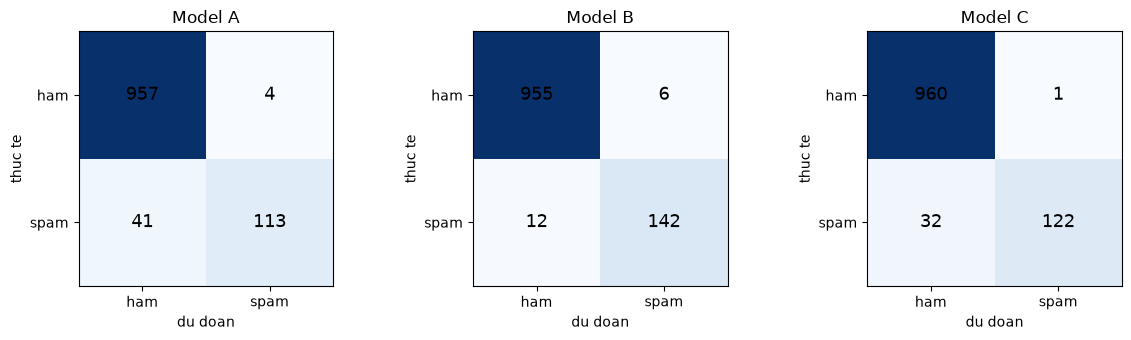

In [9]:
labels = ["ham", "spam"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (ten, y_pred) in zip(axes, [("Model A", pred_A), ("Model B", pred_B), ("Model C", pred_C)]):
    cm = np.zeros((2, 2), dtype=int)
    for a, b in zip(y_test, y_pred):
        cm[labels.index(a), labels.index(b)] += 1
    ax.imshow(cm, cmap="Blues")
    ax.set_title(ten)
    ax.set_xlabel("du doan")
    ax.set_ylabel("thuc te")
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
plt.tight_layout()
plt.show()

## 9. Top 10 từ theo log likelihood ratio

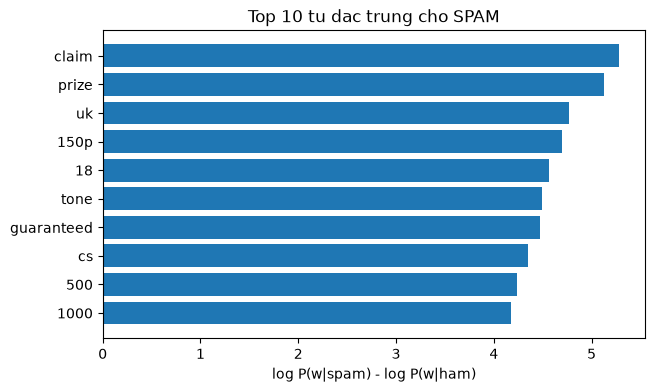

Top 10 spam: [('claim', 5.28), ('prize', 5.13), ('uk', 4.77), ('150p', 4.7), ('18', 4.56), ('tone', 4.49), ('guaranteed', 4.47), ('cs', 4.35), ('500', 4.24), ('1000', 4.18)]
Top 10 ham : [('said', -3.45), ('cos', -3.48), ('morning', -3.48), ('ok', -3.59), ('ask', -3.59), ('come', -3.8), ('much', -3.8), ('later', -3.94), ('da', -4.0), ('lor', -4.15)]


In [10]:
ti_so = [(vocab[j], p_word_B["spam"][j] - p_word_B["ham"][j]) for j in range(V)]
ti_so.sort(key=lambda t: t[1], reverse=True)

top10_spam = ti_so[:10]
top10_ham = ti_so[-10:]

plt.figure(figsize=(7, 4))
plt.barh([w for w, _ in top10_spam][::-1], [r for _, r in top10_spam][::-1])
plt.title("Top 10 tu dac trung cho SPAM")
plt.xlabel("log P(w|spam) - log P(w|ham)")
plt.show()

print("Top 10 spam:", [(w, round(r, 2)) for w, r in top10_spam])
print("Top 10 ham :", [(w, round(r, 2)) for w, r in top10_ham])

## 10. False positive / false negative của Model B

In [11]:
fp = [i for i in range(len(y_test)) if y_test[i] == "ham" and pred_B[i] == "spam"]
fn = [i for i in range(len(y_test)) if y_test[i] == "spam" and pred_B[i] == "ham"]
print("So false positive:", len(fp), "| so false negative:", len(fn))

print("\n-- FALSE POSITIVE --")
for i in fp:
    print(" ", i, test["text"].iloc[i][:75])

print("\n-- FALSE NEGATIVE --")
for i in fn:
    print(" ", i, test["text"].iloc[i][:75])

So false positive: 6 | so false negative: 12

-- FALSE POSITIVE --
  69 Nokia phone is lovly..
  342  and  picking them up from various points
  708 I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS
  728 26th OF JULY
  1073 Unlimited texts. Limited minutes.
  1088 Can u get pic msgs to your phone?

-- FALSE NEGATIVE --
  217 Do you ever notice that when you're driving, anyone going slower than you i
  222 Xmas & New Years Eve tickets are now on sale from the club, during the day 
  275 FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like
  410 ringtoneking 84484
  431 LIFE has never been this much fun and great until you came in. You made it 
  507 thesmszone.com lets you send free anonymous and masked messages..im sending
  749 How come it takes so little time for a child who is afraid of the dark to b
  832 dating:i have had two of these. Only started after i sent a text to talk sp
  839 Latest News! Police station toilet stolen, cops

In [12]:
def giai_thich(text):
    doc = tokenize(text)
    print(text[:70])
    print("  tokens:", doc)
    for w in doc:
        if w in word2idx:
            j = word2idx[w]
            print("   %-14s log P(w|spam) = %6.2f | log P(w|ham) = %6.2f"
                  % (w, p_word_B["spam"][j], p_word_B["ham"][j]))
        else:
            print("   %-14s (OOV - khong co trong tu vung)" % w)
    print()


print("### 3 FALSE POSITIVE ###")
for i in [69, 728, 1073]:
    giai_thich(test["text"].iloc[i])

print("### 3 FALSE NEGATIVE ###")
for i in [217, 410, 222]:
    giai_thich(test["text"].iloc[i])

### 3 FALSE POSITIVE ###
Nokia phone is lovly..
  tokens: ['nokia', 'phone', 'lovly']
   nokia          log P(w|spam) =  -5.91 | log P(w|ham) =  -9.39
   phone          log P(w|spam) =  -6.34 | log P(w|ham) =  -6.28
   lovly          (OOV - khong co trong tu vung)

26th OF JULY
  tokens: ['26th', 'july']
   26th           log P(w|spam) =  -9.09 | log P(w|ham) = -10.49
   july           log P(w|spam) =  -8.68 | log P(w|ham) = -10.49

Unlimited texts. Limited minutes.
  tokens: ['unlimited', 'texts', 'limited', 'minutes']
   unlimited      log P(w|spam) =  -7.38 | log P(w|ham) =  -9.39
   texts          log P(w|spam) =  -7.01 | log P(w|ham) =  -8.54
   limited        (OOV - khong co trong tu vung)
   minutes        log P(w|spam) =  -8.39 | log P(w|ham) =  -7.44

### 3 FALSE NEGATIVE ###
Do you ever notice that when you're driving, anyone going slower than 
  tokens: ['ever', 'notice', 'driving', 'anyone', 'going', 'slower', 'idiot', 'everyone', 'driving', 'faster', 'maniac']
   ever     

**3 false positive (tin ham bị đoán thành spam):**

- `"Nokia phone is lovly.."`: `nokia` gặp trong 35/593 văn bản spam nhưng chỉ 2/3864 văn bản ham
  (log P(spam) = -5.91 so với log P(ham) = -9.39), một mình nó đủ kéo cả câu sang spam. Câu chỉ có 3 token,
  lại thêm `lovly` là lỗi chính tả nên bị coi là OOV.
- `"26th OF JULY"`: cả `26th` và `july` đều **chưa từng** xuất hiện trong lớp ham, nhưng nhờ làm trơn add-one
  nên chúng vẫn nghiêng về spam và quyết định luôn kết quả vì câu quá ngắn.
- `"Unlimited texts. Limited minutes."`: các từ `unlimited`, `texts` đều là từ vựng quảng cáo dịch vụ di động
  (rất phổ biến trong spam); thực ra nội dung câu này cũng khó nói là ham.

**3 false negative (tin spam bị đoán thành ham):**

- `"Do you ever notice that when you're driving, anyone going slower than you is an idiot..."` (tin chuyển tiếp):
  các từ đều quen thuộc với lớp ham, `driving` và `fast` còn chưa từng xuất hiện trong lớp spam,
  câu không có từ khoá nào kiểu `free/call/claim` nên model chỉ thấy "văn phong trò chuyện".
- `"ringtoneking 84484"`: chỉ có 2 token, trong đó `84484` là OOV nên bị bỏ qua, còn `ringtoneking`
  chưa từng có trong lớp ham. Kết quả gần như chỉ dựa vào prior (ham nhiều gấp 6.5 lần spam) nên spam thua đúng 0.07 nat.
- `"Xmas & New Years Eve tickets are now on sale from the club..."`: nội dung giống một thông báo bán vé thật,
  số từ trung tính (`day`, `night`, `week`, `new`) nhiều hơn số từ mang hơi hướng spam nên kết quả sát nút
  (log P(ham) = -146.18 so với log P(spam) = -150.35).

## 11. Thảo luận

### a) Vấn đề xác suất bằng 0

In [13]:
so_tu_bang_0 = sum(1 for j in range(V) if count_spam[j] == 0)
print("So tu khong he xuat hien trong lop spam:", so_tu_bang_0, "/", V)

# đếm số văn bản test mà Model A cho lớp spam điểm -inf
dem = 0
for doc in test_tokens:
    diem = 0
    for w in doc:
        if w in word2idx:
            diem += p_word_A["spam"][word2idx[w]]
    if diem == -np.inf:
        dem += 1
print("So van ban test co log P(spam) = -inf:", dem, "/", len(test_tokens))

So tu khong he xuat hien trong lop spam: 5213 / 7650
So van ban test co log P(spam) = -inf: 896 / 1115


Với alpha = 0, từ nào không có trong lớp spam thì $P(w|spam) = 0$ và $\log P(w|spam) = -\infty$,
chỉ cần **một** từ như vậy là điểm của cả lớp spam thành $-\infty$, các từ còn lại có tốt đến đâu cũng vô nghĩa.
Vì 5,213/7,650 từ trong từ vựng không hề có trong lớp spam nên **896/1,115 văn bản test (80%)** bị $-\infty$ điểm spam,
model buộc phải đoán ham -> Model A bỏ sót 41/154 tin spam (Recall 0.7338) trong khi Model B chỉ bỏ sót 12 (0.9221).
Model B cộng thêm 1 vào mọi từ nên xác suất không bao giờ bằng 0, log luôn tính được.

### b) Giả định độc lập bị vi phạm

In [14]:
for cau in ["bad", "not bad", "good", "not good"]:
    doc = tokenize(cau)
    print("%-10s -> tokens %-16s -> du doan: %s" % (cau, doc, predict_multinomial([doc], p_word_B, prior)[0]))

bad        -> tokens ['bad']          -> du doan: ham
not bad    -> tokens ['bad']          -> du doan: ham
good       -> tokens ['good']         -> du doan: ham
not good   -> tokens ['good']         -> du doan: ham


Naive Bayes coi các từ độc lập với nhau nên $P(\text{not bad}|y) = P(\text{not}|y) \cdot P(\text{bad}|y)$,
trong khi thực tế `not` đảo ngược nghĩa của `bad`.
Trong ví dụ trên, `"not bad"` và `"bad"` cho ra cùng vector đặc trưng (`["bad"]`, vì `not` bị lọc như stop-word)
nên model dự đoán giống hệt nhau - hai câu trái nghĩa bị xử lý như một.
Kể cả giữ lại `not` thì model cũng chỉ **cộng thêm** log xác suất của `not` chứ không có cách nào đảo nghĩa,
nên kết quả không đổi. Tương tự, nếu một từ bị lặp lại trong câu thì điểm được cộng dồn như thể đó là nhiều
bằng chứng độc lập, làm model tự tin quá mức với các tin nhắn lặp từ/quảng cáo dồn dập.

### c) Multinomial và Bernoulli

In [15]:
for c in ["ham", "spam"]:
    tong_vang_mat = sum(float(np.log(1 - p)) for p in p_word_C[c])
    print("%-5s tong phan 'tu vang mat' = %7.2f" % (c, tong_vang_mat))

print("\nDo dai trung binh (so token):")
for c in ["ham", "spam"]:
    tb = np.mean([len(d) for d, l in zip(train_tokens, y_train) if l == c])
    print("  %-5s %.2f" % (c, tb))

ham   tong phan 'tu vang mat' =   -9.02
spam  tong phan 'tu vang mat' =  -29.42

Do dai trung binh (so token):
  ham   7.31
  spam  16.87


Bernoulli phải cộng thêm phần **từ vắng mặt** cho cả 7,650 từ. Vì các từ spam có xác suất cao hơn nên
$\log(1 - P(w|spam))$ cũng âm hơn, tổng phần vắng mặt của spam khoảng **-29.4** còn của ham chỉ **-9.0**:
lớp spam luôn bị "trừ" trước khoảng 20 nat. Vì vậy tin spam **ngắn** rất khó được đoán đúng
(phải kiếm hơn 20 nat chỉ từ vài từ có mặt), nên Model C có Precision rất cao (0.9919, chỉ 1 FP)
nhưng Recall thấp (0.7922, bỏ sót 32 spam). Ngược lại tin ham dài dễ bị đoán thành spam.

Với SMS (ngắn, trung bình ham 7.3 token và spam 16.9 token) thì **Multinomial** hợp hơn vì tần suất lặp
là tín hiệu thật (`free free`, `call now now`) và chỉ phải tính cho các từ thực sự có trong văn bản,
trong khi Bernoulli tốn công duyệt cả từ vựng và bỏ qua tần suất. Bernoulli phù hợp hơn khi thông tin nằm ở
**sự có mặt của từ khoá** trong văn bản dài.

## 12. Kết luận

- Model B (Multinomial + Laplace alpha = 1) tốt nhất: F1 = 0.9404, Recall = 0.9221.
- Model C rất thận trọng khi kết luận spam: Precision = 0.9919 nhưng Recall = 0.7922.
- Model A cho thấy rõ tác hại của việc không làm trơn: Recall chỉ 0.7338 do gặp $\log P(spam) = -\infty$.